## Zadání

### Cíl:

Budete analyzovat denní teplotní údaje v Plzni, abyste zjistili, které roky byly výrazně teplejší nebo chladnější ve srovnání s historickým průměrem.

### Úkoly:

#### Část 1 - Sběr a příprava dat

Získejte denní průměrné teploty vzduchu pro Plzeň (49°44′51″N 13°22′39″E) od roku 2018 do současnosti.

**Pozor: některá data mohou chybět (budou mít hodnoti NaN) a některé roky jsou kratší (můžete roky zarovnat na délku 364 dní).**

#### Část 2 - Vizualizace a analýza

- Vykreslete denní teplotní křivky pro každý rok do stejného grafu.
- Pro každý den v roce (bez ohledu na rok) vypočítejte průměrnou teplotu napříč všemi roky.
- Vykreslete tento průměrný roční teplotní průběh („klimatická křivka“).
- Vypočítejte průměrnou roční teplotu pro každý rok.
- Vykreslete vývoj průměrné roční teploty s 95% intervaly spolehlivosti.

#### Část 3 - Testování statistických hypotéz

Porovnáte rozložení teplot v jednotlivých letech s celkovým víceletým průměrem Nechť α=0.01 je (hladina významnosti).

H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr.
H1: Teploty v daném roce se liší / jsou teplejší / chladnější než průměr.

A. Nepárové testy - ignorujte, že dny si odpovídají
1. Identifikujte roky statisticky odlišné od celkového průměru (oboustranný test).
2. Identifikujte roky statisticky teplejší než průměr (jednostranný test).
3. Identifikujte roky statisticky chladnější než průměr (jednostranný test).

B. Párové testy - berte v úvahu, že dny si vzájemně odpovídají
1. Identifikujte roky statisticky odlišné od průměru (oboustranný test).
2. Identifikujte roky statisticky teplejší než průměr (jednostranný test).
3. Identifikujte roky statisticky chladnější než průměr (jednostranný test).

#### Část 4 - Ověření normality
Ověřte, zda rozdíl od průměrné teplovy v daném dni v roce lze považovat za normální rozdělení.
Ověření proveďte přinejmenším vizuálně.

#### Část 5 - Ověření existence trendu
Určete trend, který meziročně data vykazují použitím lineární regrese.
Ověřte na hladině významnosti α=0.01, zda je tento trend statisticky významný.

### Nápověda

Chceme-li učinit statistický závěr, že jedna sada dat je větší, menší nebo odlišná od druhé sady, musíme nejprve formulovat nulovou hypotézu:

H₀: obě sady dat pocházejí ze stejného rozdělení (nebo mezi nimi není rozdíl).

K ní pak stanovíme alternativní hypotézu:

H₁: první sada dat je větší, menší nebo jiná než druhá sada.

Při testování získáme p-hodnotu. Pokud je p-hodnota menší než zvolená hladina významnosti (např. 0.01), zamítáme H₀ a přijímáme H₁.


Nulová hypotéza nemá být formulována jako výsledek, který chceme dokázat. Smyslem testu není potvrdit, že mezi sadami je rozdíl, ale pokusit se **vyvrátit** předpoklad, že žádný rozdíl neexistuje. Statistické testování funguje asymetricky: můžeme spolehlivě odmítnout H₀, pokud máme dost důkazů, ale nikdy ji nemůžeme jednoznačně potvrdit. Proto je H₀ vždy formulována jako „žádný rozdíl“ nebo „žádný efekt“, nikoli jako naše očekávané tvrzení.

## Vypracování

### Část 1 - Sběr a příprava dat

Nejprve instalace knihoven z repozitáře.

In [ ]:
!pip install meteostat

Získání dat - **upraveno!**

- Načítání dat od 1.1.2018 do aktuálního datumu-2 dny (pro úplnost denních záznamů)

- Rozděleno přesně na roky pro lepší a konkrétnější vizualizaci

In [ ]:
from meteostat import Daily, Point
from datetime import datetime, timedelta

# Pilsen: 49°44′51″N 13°22′39″E
place = Point(49 + 44/60 + 51/3600, 13 + 22/60 + 39/3600)

current_date = datetime.now()

data = {}
for year in range(2018, 2025 + 1):
    start_date = datetime(year, 1, 1)

    if year == 2025:
        end_date = current_date - timedelta(days=2)
    else:
        end_date = datetime(year, 12, 31)

    data[year] = Daily(place, start_date, end_date).fetch()


In [ ]:
print(data[2025])

            tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt    pres   tsun
time                                                                     
2025-01-01   1.8  -2.4   6.1   0.0  <NA>  <NA>  18.3  46.3  1022.6  261.0
2025-01-02   4.0  -0.6   7.1   8.5  <NA>  <NA>  16.2  44.5  1012.7    1.0
2025-01-03  -0.1  -1.0   0.9   0.0  <NA>  <NA>  17.3  38.9  1017.9    0.0
2025-01-04  -0.9  -4.0   1.4   0.0  <NA>  <NA>  10.2  35.2  1021.4    3.0
2025-01-05  -2.3  -4.6   2.0   7.0  <NA>  <NA>   6.8  16.7  1008.8    0.0
...          ...   ...   ...   ...   ...   ...   ...   ...     ...    ...
2025-12-02   2.0   1.0   3.3   0.0  <NA>  <NA>   6.4  16.7  1018.2   73.0
2025-12-03   0.5   0.3   0.9   0.0  <NA>  <NA>   6.8  14.8  1017.4   40.0
2025-12-04   1.3   0.5   2.2   0.0  <NA>  <NA>   6.8  14.8  1013.3   26.0
2025-12-05   2.3   1.7   3.3   0.8  <NA>  <NA>   8.0  20.4  1013.4    0.0
2025-12-06   2.1   0.7   3.5   0.0  <NA>  <NA>   6.6  16.7  1014.7   79.0

[340 rows x 10 columns]


**Úprava!** - doplnění chybějících dat (jen průměrné teploty) pro rok 2025 jako průměr z předchozích let.

- Dle konkrétních datumů z předchozích let, aby odpovídala teplota

- K předpřípravě na párové testy dále

In [ ]:
import pandas as pd

data_2025 = data[2025]

# Rozsah roku 2025 a seznam chybějících dnů
datumy_2025 = pd.date_range(datetime(2025, 1, 1), datetime(2025, 12, 31))
chybejici_dny = datumy_2025.difference(data_2025.index)
print(chybejici_dny)

# Výpočet průměrů teplot z předchozích let pro každý chybějící den
nove_radky = []

for chybejici_den in chybejici_dny:
    month = chybejici_den.month
    day = chybejici_den.day
    stejne_dny = []

    for year in range(2018, 2025):
        try:
            d = data[year].loc[datetime(year, month, day)]
            if not pd.isna(d['tavg']):
                stejne_dny.append(d['tavg'])
        except KeyError:
            pass

    if stejne_dny:
        tavg = sum(stejne_dny) / len(stejne_dny)
    else:
        tavg = None

    nove_radky.append([chybejici_den, tavg])

# Nový seznam pro rok 2025 - sloučením předchozích a dopočtených hodnot
doplnena_data = pd.DataFrame(nove_radky, columns=["time", "tavg"]).set_index("time")
data_2025_komplet = pd.concat([data_2025, doplnena_data]).sort_index()
data[2025] = data_2025_komplet

DatetimeIndex(['2025-12-07', '2025-12-08', '2025-12-09', '2025-12-10',
               '2025-12-11', '2025-12-12', '2025-12-13', '2025-12-14',
               '2025-12-15', '2025-12-16', '2025-12-17', '2025-12-18',
               '2025-12-19', '2025-12-20', '2025-12-21', '2025-12-22',
               '2025-12-23', '2025-12-24', '2025-12-25', '2025-12-26',
               '2025-12-27', '2025-12-28', '2025-12-29', '2025-12-30',
               '2025-12-31'],
              dtype='datetime64[ns]', freq='D')


Ukázka, jak vypadají načtená data.

In [ ]:
print(data[2018])
print('-------------------------------------------------------------------------')
print(data[2020])
print('-------------------------------------------------------------------------')
print(data[2025])

            tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt    pres  tsun
time                                                                    
2018-01-01   5.8   2.0   9.0  <NA>  <NA>  <NA>  12.2  <NA>  1006.4  <NA>
2018-01-02   4.2   1.0   5.0  <NA>  <NA>  <NA>  14.6  <NA>  1008.9  <NA>
2018-01-03   4.8   1.0   8.0  <NA>  <NA>  <NA>  19.9  <NA>   999.0  <NA>
2018-01-04   5.0   4.0   6.0  <NA>  <NA>  <NA>  15.5  <NA>   999.6  <NA>
2018-01-05   7.8   6.0  10.0  <NA>  <NA>  <NA>  15.7  <NA>  1000.8  <NA>
...          ...   ...   ...   ...   ...   ...   ...   ...     ...   ...
2018-12-27   3.6   2.3   5.4  <NA>  <NA>  <NA>  11.7  24.1  1028.4  <NA>
2018-12-28   2.6   0.7   6.2  <NA>  <NA>  <NA>  10.6  25.9  1027.8  <NA>
2018-12-29   1.6   0.8   2.2  <NA>  <NA>  <NA>  15.9  31.5  1030.8  <NA>
2018-12-30   3.9   1.7   5.0  <NA>  <NA>  <NA>  18.5  37.0  1026.1  <NA>
2018-12-31   4.3   3.3   5.3  <NA>  <NA>  <NA>  10.4  25.9  1031.5  <NA>

[365 rows x 10 columns]
--------------------------

**Úprava!** - Zarovnání přestupných roků (2020 a 2024) na standartní délku (365 dní)

- odstranění řádku, který odpovídá přestupným rokům, konkrétně řádek odpovídající datumu 29.2.

In [ ]:
# Přestupné roky, které chceme kontrolovat
Přestupné_roky = [2020, 2024]

for year in Přestupné_roky:
    datumy = data[year]
    prestupny_den = f"{year}-02-29"

    print(f"\nKontrola roku {year} kolem 29.2.")
    # Ověření, zda datum existuje - výpis okolních hodnot a jeho odstranění
    if prestupny_den in datumy.index:
        print(datumy.loc[pd.date_range(f"{year}-02-28", f"{year}-03-01")])
        data[year] = datumy.drop(prestupny_den)
        print(f"--> Datum {prestupny_den} byl odstraněn.\n")
    else:
        print(f"Datum {prestupny_den} v roce {year} nebyl nalezen.\n")



Kontrola roku 2020 kolem 29.2.
            tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt    pres  tsun
2020-02-28   1.6  -0.6   4.2  <NA>  <NA>  <NA>  15.6  40.8  1013.7  <NA>
2020-02-29   4.8  -0.2   9.8  <NA>  <NA>  <NA>  10.8  25.9  1005.3  <NA>
2020-03-01   7.2   4.2  10.6  <NA>  <NA>  <NA>  16.1  48.2  1001.6  <NA>
--> Datum 2020-02-29 byl odstraněn.


Kontrola roku 2024 kolem 29.2.
            tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt    pres   tsun
2024-02-28   6.1   4.4   9.0   0.0  <NA>  <NA>   5.2  14.8  1020.3   67.0
2024-02-29   5.3   3.0   9.4   0.0  <NA>  <NA>   8.3  22.2  1017.2  179.0
2024-03-01   6.1   3.5   9.2   2.1  <NA>  <NA>   6.4  20.4  1008.1  140.0
--> Datum 2024-02-29 byl odstraněn.



In [ ]:
print(data[2020])
print('-------------------------------------------------------------------------')
print(data[2024])
print('-------------------------------------------------------------------------')

            tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt    pres  tsun
time                                                                    
2020-01-01  -2.1  -4.9   1.8  <NA>  <NA>  <NA>   5.1  14.8  1036.6  <NA>
2020-01-02  -4.2  -7.3  -1.3  <NA>  <NA>  <NA>   6.5  16.7  1031.9  <NA>
2020-01-03   0.5  -4.7   4.6  <NA>  <NA>  <NA>  11.7  38.9  1025.3  <NA>
2020-01-04   3.4   1.8   5.5  <NA>  <NA>  <NA>  18.7  42.6  1025.7  <NA>
2020-01-05   0.8  -1.2   3.4  <NA>  <NA>  <NA>  10.5  33.3  1035.1  <NA>
...          ...   ...   ...   ...   ...   ...   ...   ...     ...   ...
2020-12-27  -1.8  -3.4   0.1  <NA>  <NA>  <NA>   8.6  20.4  1006.7  <NA>
2020-12-28  -0.7  -1.7   0.3  <NA>  <NA>  <NA>   7.6  16.7   986.2  <NA>
2020-12-29   1.4  -1.2   5.4  <NA>  <NA>  <NA>  12.4  46.3   992.5  <NA>
2020-12-30  -0.5  -3.0   2.2  <NA>  <NA>  <NA>   6.2  16.7  1005.4  <NA>
2020-12-31   0.8  -2.2   3.6  <NA>  <NA>  <NA>   6.4  14.8  1009.1  <NA>

[365 rows x 10 columns]
--------------------------

**Úprava!** - Nalezení NaN hodnot tavg pro konkrétní datum (všechny v roce 2018)

- nahrazení NaN tavg hodnot průměrem z ostatních let

In [ ]:
# Nalezení NaN hodnot
for year in data:
    datumy = data[year]

    # Nalezení řádků, kde je tavg = NaN
    NaN_radky = datumy[datumy['tavg'].isna()]

    if len(NaN_radky) > 0:
        print(f"\n===== Rok {year} – nalezeny NaN hodnoty =====")
        print(NaN_radky)


# Přepočet NaN hodnot na průměry
data_2018 = data[2018]
NaN_dny = data_2018[data_2018['tavg'].isna()].index
nove_radky = []

for chybejici_den in NaN_dny:
    month = chybejici_den.month
    day = chybejici_den.day

    stejne_datumy = []

    # Stejné datum pro ostatní roky 2019–2025 - víme, že chyby jsou jen v roku 2018
    for year in range(2019, 2026):
        try:
            d = data[year].loc[datetime(year, month, day)]
            if not pd.isna(d['tavg']):
                stejne_datumy.append(d['tavg'])
        except KeyError:
            pass

    if len(stejne_datumy) > 0:
        tavg = sum(stejne_datumy) / len(stejne_datumy)

    nove_radky.append([chybejici_den, tavg])

# Upravená data pro rok 2018
doplnena_data = pd.DataFrame(nove_radky, columns=["time", "tavg"]).set_index("time")
data_2018.loc[doplnena_data.index, "tavg"] = doplnena_data["tavg"]
data[2018] = data_2018

print(data[2018].loc["2018-07-16":"2018-07-20"])


===== Rok 2018 – nalezeny NaN hodnoty =====
            tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt  pres  tsun
time                                                                  
2018-01-13  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
2018-02-02  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
2018-02-03  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
2018-05-15  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
2018-07-17  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
2018-07-18  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
2018-07-19  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>
                 tavg  tmin  tmax  prcp  snow  wdir  wspd  wpgt    pres  tsun
time                                                                         
2018-07-16       18.5  13.0  25.0  <NA>  <NA>  <NA>   4.4  <NA>  1014.3  <NA>
2018-07-17  18.442857  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>  <NA>    <NA>  <NA>
2018

**Úprava !** - jen převod na numpy pole, veškerá zarovnání a NaN hodnoty jsou již vyřešeny

- Nyní tedy máme 2920 hodnot, pro každý rok 365 hodnot od 1.1 do 31.12.

In [ ]:
# převod na numpy pole - tavg pro každý rok + kontrola s NaN hodnotami
import numpy as np

xs = {}
for year in data:
    xs[year] = data[year]['tavg'].to_numpy()

all_year_data = []
for year in xs:
    all_year_data.append(xs[year])

x_all = np.concatenate(all_year_data)
x_all = x_all[~np.isnan(x_all)]

print(f"Očekáváno 2920 (365×8) hodnot--> Skutečná délka: {len(x_all)}")

Očekáváno 2920 (365×8) hodnot--> Skutečná délka: 2920


### Část 2 - Vizualizace a analýza

Nejprve vypočítáme průmerný průběh teplot během roku. Pozor, v datech jsou vynechané hodnoty reprezentované jako NaN.

**Úprava!** - již nemám žádné NaN hodnoty, celkový průměr pro každý den počítám i z těch dopočtených průměrů kde ty hodnoty tavg chyběly

In [ ]:
import numpy as np

# 8 řádků (roky) a 365 sloupců (teploty)
teploty_pro_roky = x_all.reshape(8, 365)
prumerna_denni_teplota = np.nanmean(teploty_pro_roky, axis=0)

Vykreslíme do jednoho grafu průběhy teplot pro každý rok. Vykreslíme i průměr a zvýrazníme ho.

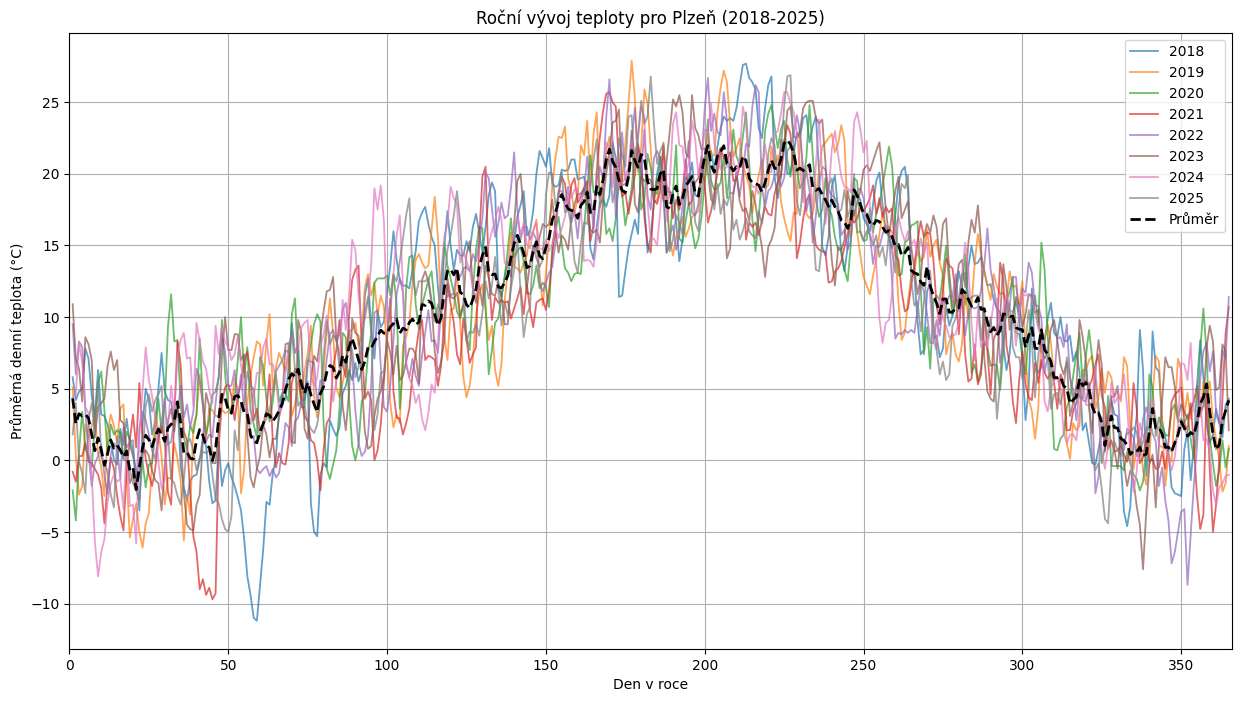

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

# Vykreslení denních průměrů pro každý rok
for year, prumerna_teplota in xs.items():
    plt.plot(range(1, 366), prumerna_teplota, label=f'{year}', alpha=0.7, linewidth=1.3)

# Vykreslení průměrné denní teploty
plt.plot(range(1, 366), prumerna_denni_teplota, color='black', linestyle='--', linewidth=2, label='Průměr')

plt.xlim(0, 366)
plt.title('Roční vývoj teploty pro Plzeň (2018-2025)')
plt.xlabel('Den v roce')
plt.ylabel('Průměrná denní teplota (°C)')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


Vykreslíme průběh průměrné roční teploty, přičemž vykreslíme oblast s 95% intervalem spočteným z hodnot teplot pro celý daný rok.

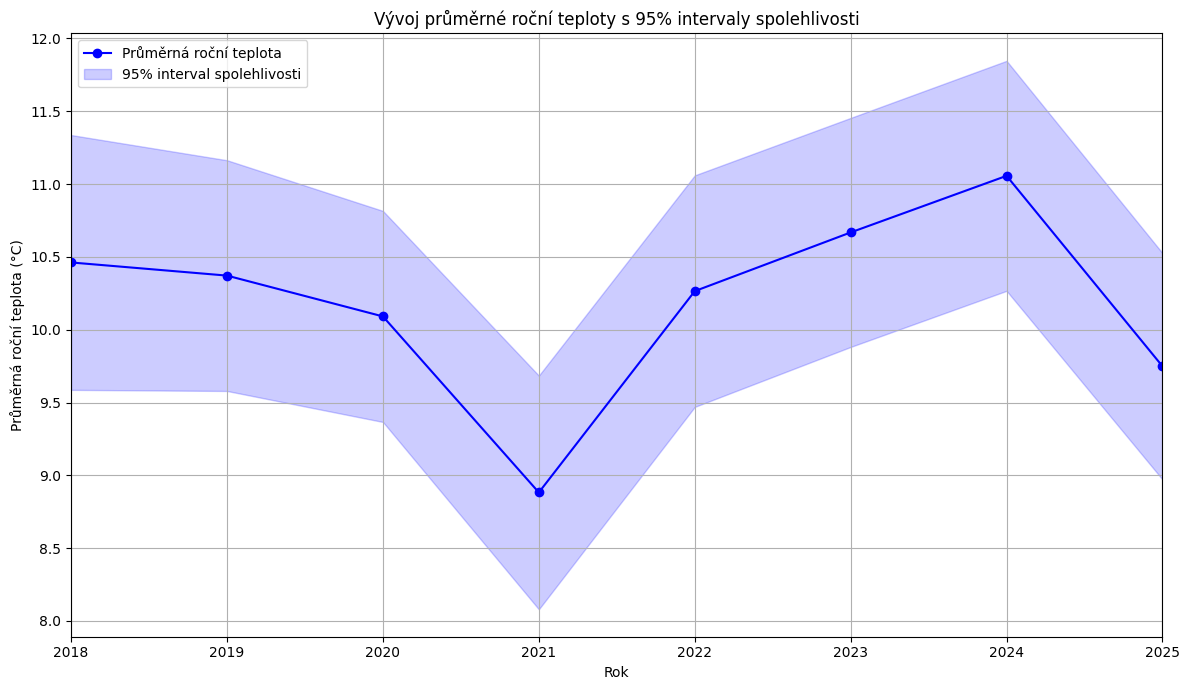

In [ ]:
from scipy import stats

years = sorted(xs.keys())
rocni_prumery = []
intervaly_spolehlivosti = []

# Výpočet průměrných ročních teplot a 95-% intervalů spolehlivosti
for year in years:
    tavg_data = xs[year]

    prumerna_rocni_teplota = np.mean(tavg_data)
    stand_chyba_prumeru = stats.sem(tavg_data)
    spodni_hranice, horni_hranice = stats.t.interval(0.95, df=len(tavg_data)-1, loc=prumerna_rocni_teplota, scale=stand_chyba_prumeru)

    rocni_prumery.append(prumerna_rocni_teplota)
    intervaly_spolehlivosti.append((spodni_hranice, horni_hranice))

# Spodní a dolní hranice intervalů spolehlivosti k vykreslení grafu
spodni_hranice_all = []
horni_hranice_all = []
for x in intervaly_spolehlivosti:
  spodni_hranice_all.append(x[0])
  horni_hranice_all.append(x[1])

# Vykreslení grafu
plt.figure(figsize=(12, 7))
plt.plot(years, rocni_prumery, marker='o', linestyle='-', color='blue', label='Průměrná roční teplota')
plt.fill_between(years, spodni_hranice_all, horni_hranice_all, color='blue', alpha=0.2, label='95% interval spolehlivosti')

plt.xlim(years[0], years[-1])
plt.title('Vývoj průměrné roční teploty s 95% intervaly spolehlivosti')
plt.xlabel('Rok')
plt.ylabel('Průměrná roční teplota (°C)')
plt.xticks(years)
plt.grid(True)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Část 3 - Testování statistických hypotéz


In [ ]:
p_val_threshold = 0.01

Využijeme tyto standardní knihovny pro testování hypotéz:

In [ ]:
from scipy.stats import ttest_ind, ttest_rel

#### Nepárové testy

Nejprve budeme ignorovat, že dny si odpovídají

1) Identifikujte roky statisticky odlišné od celkového průměru (oboustranný test).

In [ ]:
# H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr.
# H1: Teploty v daném roce se statisticky liší od celkového průměru.

odlisne_roky = []

for year in xs:
    this_year = xs[year]

    other_years = []
    for other_year, other_year_teploty in xs.items():
        if other_year != year:
            other_years.append(other_year_teploty)

    other_years_komplet = np.concatenate(other_years)

    # Nepárový t-test s alternative='two-sided' pro oboustranný test
    # equal_var=False, protože nepředpokládáme stejné rozptyly
    t_stat, p_val = ttest_ind(this_year, other_years_komplet, alternative='two-sided', equal_var=False)

    if p_val < p_val_threshold:
        odlisne_roky.append(year)

print(f"Roky statisticky odlišné od celkového průměru (α={p_val_threshold}): {odlisne_roky}")

Roky statisticky odlišné od celkového průměru (α=0.01): [2021]


2. Identifikujte roky statisticky teplejší než průměr (jednostranný test).

In [ ]:
# H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr (nejsou teplejší).
# H1: Teploty v daném roce jsou statisticky teplejší než celkový průměr.

teplejsi_roky = []

for year in xs:
    this_year = xs[year]

    other_years = []
    for other_year, other_year_teploty in xs.items():
        if other_year != year:
            other_years.append(other_year_teploty)

    other_years_komplet = np.concatenate(other_years)

    # Nepárový t-test s alternative='greater' pro jednostranný test (teplejší)
    t_stat, p_val = ttest_ind(this_year, other_years_komplet, alternative='greater', equal_var=False)

    if p_val < p_val_threshold:
        teplejsi_roky.append(year)

print(f"Roky statisticky teplejší než průměr (α={p_val_threshold}): {teplejsi_roky}")

Roky statisticky teplejší než průměr (α=0.01): []


3. Identifikujte roky statisticky chladnější než průměr (jednostranný test).

In [ ]:
# H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr (nejsou chladnější).
# H1: Teploty v daném roce jsou statisticky chladnější než celkový průměr.

chladnejsi_roky = []

for year in xs:
    this_year = xs[year]

    other_years = []
    for other_year, other_year_teploty in xs.items():
        if other_year != year:
            other_years.append(other_year_teploty)

    other_years_komplet = np.concatenate(other_years)

    # Nepárový t-test s alternative='less' pro jednostranný test (chladnější)
    t_stat, p_val = ttest_ind(this_year, other_years_komplet, alternative='less', equal_var=False)

    if p_val < p_val_threshold:
        chladnejsi_roky.append(year)

print(f"Roky statisticky chladnější než průměr (α={p_val_threshold}): {chladnejsi_roky}")

Roky statisticky chladnější než průměr (α=0.01): [2021]


#### Párové testy

Budeme brát  v úvahu, že dny si vzájemně odpovídají

1. Identifikujte roky statisticky odlišné od průměru (oboustranný test).

In [ ]:
# H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr.
# H1: Teploty v daném roce se statisticky liší od celkového průměru.

odlisne_roky_parove = []

for year in xs:
    this_year = xs[year]

    # Párový t-test s alternative='two-sided' pro oboustranný test
    t_stat, p_val = ttest_rel(this_year, prumerna_denni_teplota, alternative='two-sided')

    if p_val < p_val_threshold:
        odlisne_roky_parove.append(year)

print(f"Roky statisticky odlišné od průměru (párový test, α={p_val_threshold}): {odlisne_roky_parove}")

Roky statisticky odlišné od průměru (párový test, α=0.01): [2021, 2023, 2024, 2025]


2. Identifikujte roky statisticky teplejší než průměr (jednostranný test).

In [ ]:
# H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr (nejsou teplejší).
# H1: Teploty v daném roce jsou statisticky teplejší než celkový průměr.

teplejsi_roky_parove = []

for year in xs:
    this_year = xs[year]

    # Párový t-test s alternative='greater' pro jednostranný test (teplejší)
    t_stat, p_val = ttest_rel(this_year, prumerna_denni_teplota, alternative='greater')

    if p_val < p_val_threshold:
        teplejsi_roky_parove.append(year)

print(f"Roky statisticky teplejší než průměr (párový test, α={p_val_threshold}): {teplejsi_roky_parove}")

Roky statisticky teplejší než průměr (párový test, α=0.01): [2023, 2024]


3. Identifikujte roky statisticky chladnější než průměr (jednostranný test).

In [ ]:
# H0: Teploty v daném roce pocházejí ze stejného rozdělení jako celkový průměr (nejsou chladnější).
# H1: Teploty v daném roce jsou statisticky chladnější než celkový průměr.

chladnejsi_roky_parove = []

for year in xs:
    this_year = xs[year]

    # Párový t-test s alternative='less' pro jednostranný test (chladnější)
    t_stat, p_val = ttest_rel(this_year, prumerna_denni_teplota, alternative='less')

    if p_val < p_val_threshold:
        chladnejsi_roky_parove.append(year)

print(f"Roky statisticky chladnější než průměr (párový test, α={p_val_threshold}): {chladnejsi_roky_parove}")

Roky statisticky chladnější než průměr (párový test, α=0.01): [2021, 2025]


### Diskuse nad výsledky

Pro nepárové testy vyšlo méně extrémních roků. Konkrétně pouze rok **2021** se ukázal jako statisticky odlišný i chladnější než průměr. Žádný rok nebyl statisticky teplejší.

Důvodem, proč nepárové testy identifikovaly méně statisticky odlišných let, je to, že ignorují denní závislosti. Porovnávají se pouze rozdělení teplot v daném roce s rozdělením teplot ve všech ostatních letech dohromady, což vede k větší variabilitě a vyšší pravděpodobnosti, že rozdíly nebudou shledány statisticky významnými.

Naproti tomu párové testy zohledňují, že dny si vzájemně odpovídají. Tím se snižuje variabilita, která pochází z přirozeného sezónního cyklu teplot v průběhu roku. Díky tomu jsou párové testy citlivější na menší, ale konzistentní rozdíly mezi teplotami daného roku a průměrnými teplotami pro konkrétní dny. Proto párové testy identifikovaly více statisticky odlišných let: **2021**, **2023**, **2024**, **2025**.

Konkrétně:

**2023** a **2024** byly statisticky teplejší než průměr.

**2021** a **2025** byly statisticky chladnější než průměr.

Věrohodnější výsledek je použití párového testu, protože data představují časové řady, kde každý den v roce je závislý na stejném dnu v jiném roce. Párový test je schopen lépe zachytit sezónní variace a konzistentní rozdíly v teplotách v průběhu celého roku, což je v tomto případě relevantnější pro analýzu ročního teplotního průběhu. Ignorování této korelace v nepárovém testu by mohlo vést k přehlédnutí významných rozdílů.

### Část 4 - Ověření normality

Odečteme v každém roce od teplot průměrnou teplotu v každém dni. Pro takto získané rozíly teplot vykreslíme histogram.

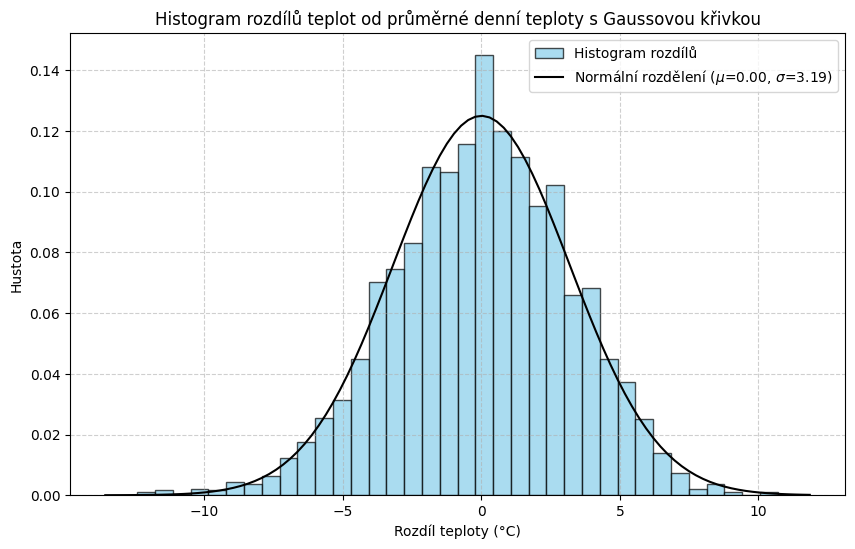

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import norm

# Odečtení průměrné denní teploty od každého roku + spojení rozdílů do pole
rozdily_teplot = []
for year in xs:
    rozdily_teplot.append(xs[year] - prumerna_denni_teplota)

all_rozdily = np.concatenate(rozdily_teplot)

# Vykreslení histogramu rozdílů
plt.figure(figsize=(10, 6))
plt.hist(all_rozdily, bins=36, density=True, alpha=0.7, color='skyblue', edgecolor='black', label='Histogram rozdílů')

# Proložení Gaussovou křivkou
str_hod, smerodat_odchylka = np.mean(all_rozdily), np.std(all_rozdily)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
y = norm.pdf(x, str_hod, smerodat_odchylka)              # Hodnoty ppstní. hustotní fce. pro normál. rozděl.
plt.plot(x, y, 'k', linewidth=1.5, label=rf'Normální rozdělení ($\mu$={str_hod:.2f}, $\sigma$={smerodat_odchylka:.2f})')

plt.title('Histogram rozdílů teplot od průměrné denní teploty s Gaussovou křivkou')
plt.xlabel('Rozdíl teploty (°C)')
plt.ylabel('Hustota')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Z histogramu je vidět, že rozložení rozdílů teplot od průměrné denní teploty je možné prohlásit za **normální**. Graf vykazuje typický zvonovitý tvar, je celkem symetrický a dobře kopíruje překrytou Gaussovu křivku. Na základě tohoto vizuálního ověření proto pokládáme předpoklady o normalitě dat, učiněné při testování hypotéz, za oprávněné.

### Část 5 - Ověření existence trendu

Vypočteme lineární regresi a vyhodnotíme p-hodnotu pro nalezený trend.
Výsledky zaneseme do grafu.

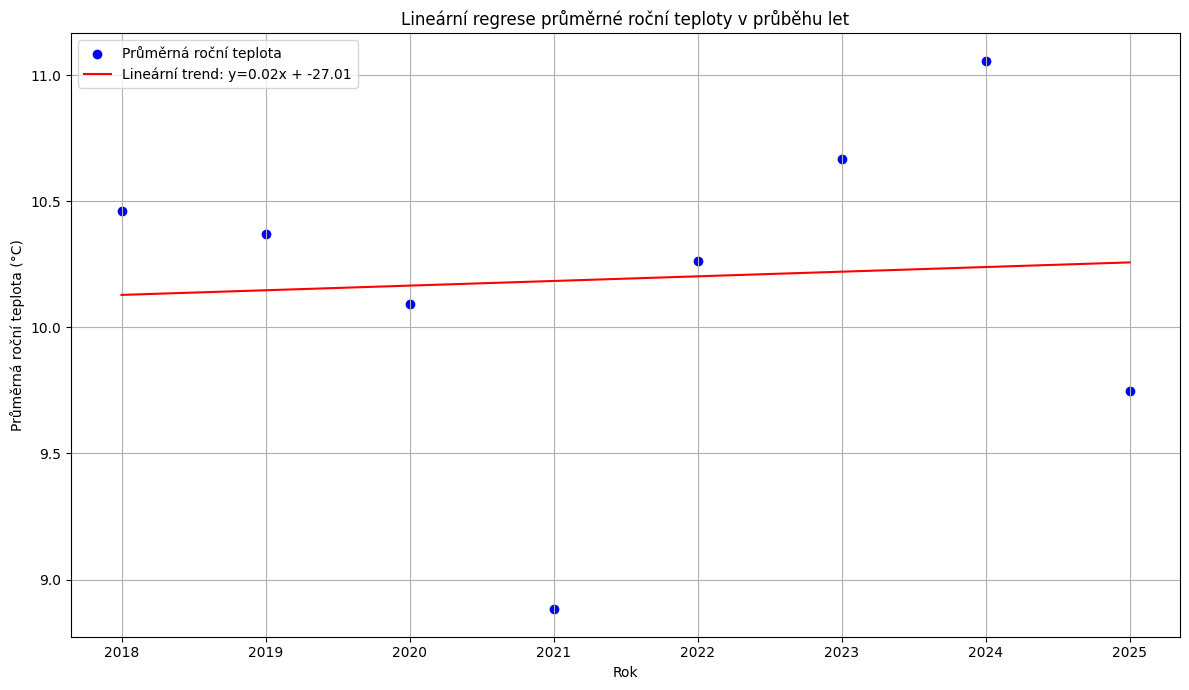

Linear regression slope: 0.0184 °C/year
Correlation (r): 0.069
p-value: 0.87141


In [ ]:
from scipy import stats
import matplotlib.pyplot as plt

# Lineární regrese
# 'years' = nezávislá proměnná (x-hodnoty) ... 'rocni_prumery' = závislá proměnná (y-hodnoty)
slope, intercept, r_value, p_val, std_err = stats.linregress(years, rocni_prumery, alternative="two-sided")
regresni_primka = [slope * year + intercept for year in years]

# Vykreslení grafu
plt.figure(figsize=(12, 7))
plt.scatter(years, rocni_prumery, color='blue', label='Průměrná roční teplota')
plt.plot(years, regresni_primka, color='red', linestyle='-', label=f'Lineární trend: y={slope:.2f}x + {intercept:.2f}')

plt.title('Lineární regrese průměrné roční teploty v průběhu let')
plt.xlabel('Rok')
plt.ylabel('Průměrná roční teplota (°C)')
plt.xticks(years)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Linear regression slope: {slope:.4f} °C/year")
print(f"Correlation (r): {r_value:.3f}")
print(f"p-value: {p_val:.5f}")

Z výsledků lineární regrese je patrné, že průměrná roční teplota vykazuje velmi mírný nárůst o přibližně **0.0184 °C za rok**.

Nicméně, vypočtená **p-hodnota je 0.87141**. To znamená, že je vysoká pravděpodobnost (87.14%), že takovýto mírný nárůst vidíme čistě náhodou, a tudíž že žádný skutečný trend neexistuje. Jelikož je tato hodnota vyšší než naše zvolená hladina významnosti α = 0.01, **nemůžeme zamítnout nulovou hypotézu**.

To znamená, že zjištěný **trend není statisticky významný** na hladině významnosti 0.01. I když data ukazují mírný nárůst, nemáme dostatek statistických důkazů, abychom mohli s 99% spolehlivostí tvrdit, že tento trend není pouhou náhodou.

**Korelace (r) je 0.069**, tudíž velmi nízká hodnota, která je blízko nule. Znamená to, že mezi rokem a průměrnou roční teplotou existuje velmi slabý, téměř zanedbatelný, pozitivní lineární vztah. Graficky to odpovídá bodům, které jsou hodně rozptýlené kolem regresní přímky a přímka je sama o sobě téměř nenakloněná.

### Bonus nad rámec zadání

**Analýza extrémních teplot pro Plzeň v letech 2018-2025**

Pro každý rok určuji počet dnů s vlnami veder, které jsou definovány maximální denní teplotou 30°C a vyšší. Zároveň určujeme počet mrazivých dnů, kde minimální denní teplota klesla na -5°C nebo níže.

Výsledkem jsou výpisy konkrétních dat těchto extrémních událostí pro každý rok. Nakonec je pro lepší vizualizaci vytvořen graf porovnávající počet horkých a mrazivých dnů v jednotlivých letech.


Horké dny (tmax >= 30°C):
  2018: 23 dní, Datumy: ['04.07.', '05.07.', '24.07.', '25.07.', '27.07.', '28.07.', '29.07.', '30.07.', '31.07.', '01.08.', '02.08.', '03.08.', '04.08.', '06.08.', '07.08.', '08.08.', '09.08.', '13.08.', '17.08.', '19.08.', '20.08.', '22.08.', '23.08.']
  2019: 18 dní, Datumy: ['03.06.', '05.06.', '12.06.', '14.06.', '15.06.', '25.06.', '26.06.', '27.06.', '29.06.', '30.06.', '06.07.', '20.07.', '23.07.', '24.07.', '25.07.', '26.07.', '18.08.', '31.08.']
  2020: 11 dní, Datumy: ['28.07.', '31.07.', '01.08.', '07.08.', '08.08.', '09.08.', '10.08.', '12.08.', '13.08.', '21.08.', '15.09.']
  2021: 6 dní, Datumy: ['17.06.', '18.06.', '19.06.', '20.06.', '06.07.', '15.08.']
  2022: 12 dní, Datumy: ['18.06.', '19.06.', '27.06.', '19.07.', '20.07.', '22.07.', '24.07.', '25.07.', '03.08.', '04.08.', '05.08.', '17.08.']
  2023: 19 dní, Datumy: ['20.06.', '22.06.', '26.06.', '08.07.', '09.07.', '10.07.', '11.07.', '15.07.', '12.08.', '14.08.', '15.08.', '19.08.', '20.0

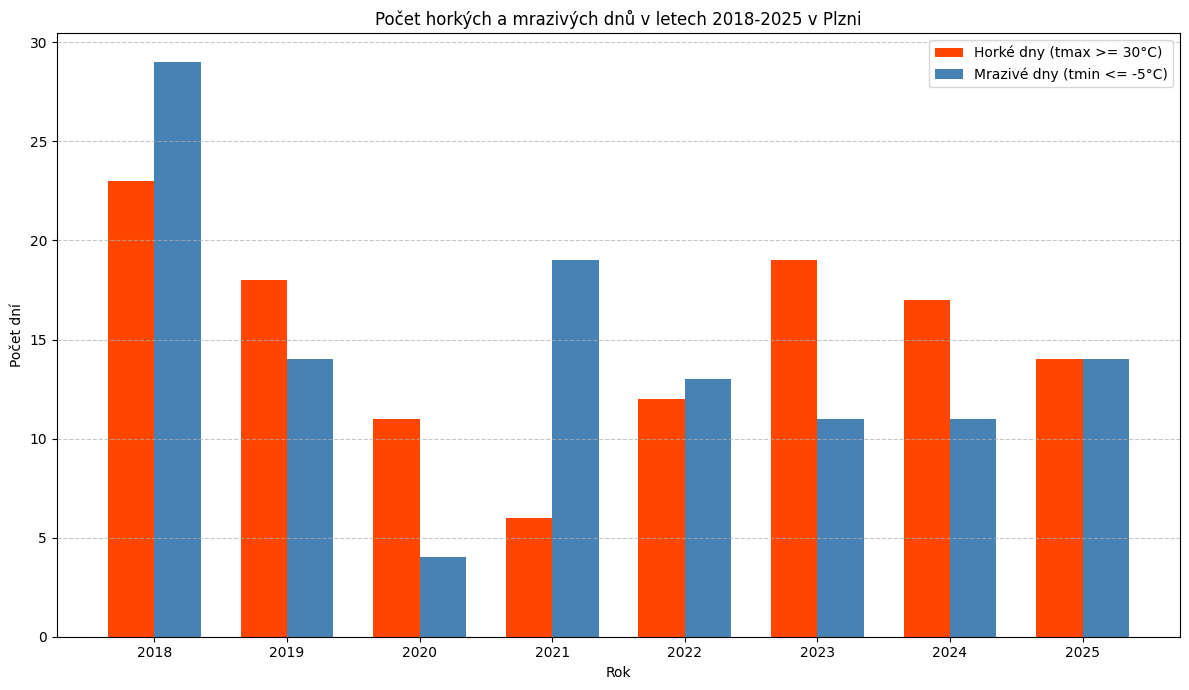

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

horke_dny = {}
mrazive_dny = {}
datumy_horke_dny = {}
datumy_mrazive_dny = {}

# Nalezení extrémních dnů
for year, polozky in data.items():
    # Horké dny (tmax >= 30°C)
    horky_den = polozky[polozky['tmax'] >= 30]
    horke_dny[year] = len(horky_den)
    datumy_horke_dny[year] = horky_den.index.strftime('%d.%m.').tolist()

    # Mrazivé dny (tmin <= -5°C)
    mrazivy_den = polozky[polozky['tmin'] <= -5]
    mrazive_dny[year] = len(mrazivy_den)
    datumy_mrazive_dny[year] = mrazivy_den.index.strftime('%d.%m.').tolist()

# Výpis počtu horkých dnů a datumů horkých dní
print("Horké dny (tmax >= 30°C):")
for year, pocet in horke_dny.items():
    print(f"  {year}: {pocet} dní, Datumy: {datumy_horke_dny[year]}")

# Výpis počtu mrazivých dnů a datumů mrazivých dní
print("\nMrazivé dny (tmin <= -5°C):")
for year, pocet in mrazive_dny.items():
    print(f"  {year}: {pocet} dní, Datumy: {datumy_mrazive_dny[year]}")

# Vykreslení grafu
years = list(horke_dny.keys())
pocet_horkych_dnu = [horke_dny[year] for year in years]
pocet_mrazivych_dnu = [mrazive_dny[year] for year in years]

x = np.arange(len(years))
width = 0.35

plt.figure(figsize=(12, 7))
bar_plot1 = plt.bar(x - width/2, pocet_horkych_dnu, width, label='Horké dny (tmax >= 30°C)', color='orangered')
bar_plot2 = plt.bar(x + width/2, pocet_mrazivych_dnu, width, label='Mrazivé dny (tmin <= -5°C)', color='steelblue')
plt.xlabel('Rok')
plt.ylabel('Počet dní')
plt.title('Počet horkých a mrazivých dnů v letech 2018-2025 v Plzni')
plt.xticks(x, years)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Z grafu je patrné, že nejextrémnějším rokem byl rok 2018, a to i přesto, že jsou v rámci tohoto úkolu pro tento rok vynechány hodnoty NaN.

Dále je vidět, že výsledky odpovídají dřívějším pozorováním, konkrétně že rok 2021 byl výrazně chladnější než ostatní roky, což dokládá i výrazný nepoměr mezi počtem horkých a mrazivých dnů. Také roky 2023 a 2024 naznačují, že patří mezi průměrně teplejší roky. U roku 2025 chybí maximální a minimální teploty pro velkou část prosince, takže lze předpokládat, že při úplném datasetu by měl tento rok mnohem více mrazivých dnů.

**Určení maximální a minimální teploty pro každý rok**

pro zajímavost přikládám ještě vývoj minimálních a maximálních ročních teplot pro roky 2018-2025.

Roční extrémní teploty (tmin, tmax):

2018: Minimální teplota = 28.02. -15.0°C, Maximální teplota = 31.07. 35.5°C
2019: Minimální teplota = 23.01. -9.7°C, Maximální teplota = 26.06. 36.1°C
2020: Minimální teplota = 02.01. -7.3°C, Maximální teplota = 21.08. 33.8°C
2021: Minimální teplota = 15.02. -15.2°C, Maximální teplota = 19.06. 33.0°C
2022: Minimální teplota = 13.12. -10.1°C, Maximální teplota = 20.07. 35.5°C
2023: Minimální teplota = 08.02. -9.9°C, Maximální teplota = 15.07. 36.0°C
2024: Minimální teplota = 09.01. -11.4°C, Maximální teplota = 24.08. 33.4°C
2025: Minimální teplota = 20.02. -11.2°C, Maximální teplota = 02.07. 35.9°C


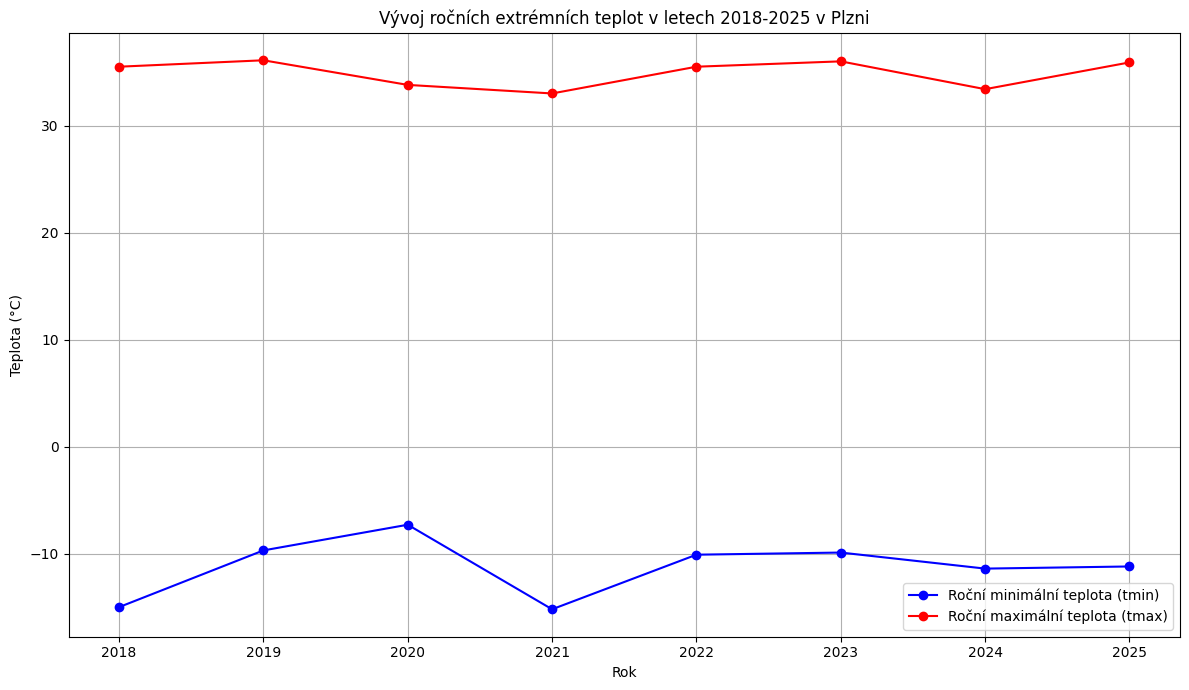

In [ ]:
minimalni_teploty = {}
maximalni_teploty = {}

for year, polozky in data.items():
    # Minimum pro každý rok
    minimalni_teplota = polozky['tmin'].min()
    datum_minimalni_teploty = polozky[polozky['tmin'] == minimalni_teplota].index[0].strftime('%d.%m.')
    minimalni_teploty[year] = {'value': minimalni_teplota, 'date': datum_minimalni_teploty}

    # Maximum pro každý rok
    maximalni_teplota = polozky['tmax'].max()
    datum_maximalni_teploty = polozky[polozky['tmax'] == maximalni_teplota].index[0].strftime('%d.%m.')
    maximalni_teploty[year] = {'value': maximalni_teplota, 'date': datum_maximalni_teploty}

# Výpis výsledků
print("Roční extrémní teploty (tmin, tmax):\n")
for year in sorted(data.keys()):
    minima = minimalni_teploty[year]
    maxima = maximalni_teploty[year]
    print(f"{year}: Minimální teplota = {minima['date']} {minima['value']:.1f}°C, Maximální teplota = {maxima['date']} {maxima['value']:.1f}°C")


# Vykreslení grafu
years = sorted(minimalni_teploty.keys())
minima_hodnoty = [minimalni_teploty[year]['value'] for year in years]
maxima_hodnoty = [maximalni_teploty[year]['value'] for year in years]

plt.figure(figsize=(12, 7))
plt.plot(years, minima_hodnoty, marker='o', linestyle='-', color='blue', label='Roční minimální teplota (tmin)')
plt.plot(years, maxima_hodnoty, marker='o', linestyle='-', color='red', label='Roční maximální teplota (tmax)')

plt.title('Vývoj ročních extrémních teplot v letech 2018-2025 v Plzni')
plt.xlabel('Rok')
plt.ylabel('Teplota (°C)')
plt.xticks(years)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Závěr

V této semestrální práci jsme provedli komplexní analýzu denních teplotních údajů v Plzni za období 2018-2025. Úspěšně jsme shromáždili a připravili data, včetně řešení chybějících hodnot a zarovnání délky let. Vizualizovali jsme denní i průměrné roční teplotní průběhy a provedli statistické testy k identifikaci let, která se statisticky významně liší od celkového průměru, a to jak párovými, tak nepárovými testy. Ověřili jsme normalitu rozložení teplotních rozdílů a prozkoumali existenci meziročního trendu pomocí lineární regrese. Veškeré komentování výsledků je přímo v práci.

Bonus nad rámec zadání:
- průměrováním dopočtené chybějící hodnoty pro rok 2025 a chybějící NaN hodnoty pro rok 2018 + odstranění přesně 29. února z let 2020 a 2024
- analyzování extrémních hodnot (horké a mrazivé dny) + vykreslení ročních extrémních teplot